In [ ]:
%pip install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


- Biblioteker for å lese og behandle datasett, gjøre beregninger og lage figurer
- Laste opp "Sleep_health_and_lifestyle_dataset.csv"
  - viser de fem første radene i datasettet

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "Sleep_health_and_lifestyle_dataset.csv",
    sep=";",    
    keep_default_na=False
)

df.head()


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


Kontrollerer størrelsen og variablene i datasettet:

In [ ]:
print("Antall observasjoner og variabler:", df.shape)
print("\nVariabler:")
print(df.columns)

Antall observasjoner og variabler: (374, 13)

Variabler:
Index(['Person ID', 'Gender', 'Age', 'Occupation', 'Sleep Duration',
       'Quality of Sleep', 'Physical Activity Level', 'Stress Level',
       'BMI Category', 'Blood Pressure', 'Heart Rate', 'Daily Steps',
       'Sleep Disorder'],
      dtype='str')


Undersøke responsvariabel:
- undersøke hvordan søvnforstyrrelser er registrert
- "None" betyr at personen ikke har en registrert søvnforstyrrelse.

In [ ]:
df["Sleep Disorder"].value_counts(dropna=False)

Sleep Disorder
None           219
Sleep Apnea     78
Insomnia        77
Name: count, dtype: int64

Lager ny binær responsvariabel for søvnforstyrrelser:
    0 = Ingen søvnforstyrrelse
    1 = Registrert Søvnforstyrrelse

In [ ]:
df["Sleep Disorder Binary"] = np.where(
    df["Sleep Disorder"] == "None", 0, 1
)

df["Sleep Disorder Binary"].value_counts()

Sleep Disorder Binary
0    219
1    155
Name: count, dtype: int64

Kontrollere 3 forklaringsvariabler:

In [ ]:
variabler = [
    "Stress Level",
    "Sleep Duration",
    "BMI Category"
]

df[variabler].head()

,Stress Level,Sleep Duration,BMI Category
0,6,6.1,Overweight
1,8,6.2,Normal
2,8,6.2,Normal
3,8,5.9,Obese
4,8,5.9,Obese


Undersøker om det finnes manglende verdier i datasettet

In [ ]:
df[variabler].isna().sum()

Stress Level      0
Sleep Duration    0
BMI Category      0
dtype: int64

Undersøke BMI-kategoriene og deres fordeling:
- "Normal" og "Normal Weight" skal slås sammen til én kategori.

In [ ]:

df["BMI Category"] = df["BMI Category"].replace(
    "Normal Weight", "Normal"
)

df["BMI Category"].value_counts()


BMI Category
Normal        216
Overweight    148
Obese          10
Name: count, dtype: int64

Gjennomsnittlig stressnivå og søvnlengde for personer med og uten registrert søvnforstyrrelse:
- Undersøker hvordan stressnivå og søvnlengde fordeler seg mellom de to klassene.

In [ ]:
df.groupby("Sleep Disorder Binary")[
    ["Stress Level", "Sleep Duration"]
].mean()


,Stress Level,Sleep Duration
Sleep Disorder Binary,,
0,5.114155,7.358447
1,5.767742,6.812258


Visualisering av stressnivået:

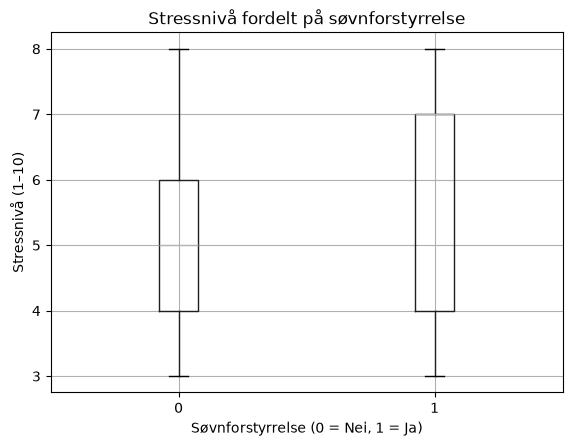

In [ ]:
df.boxplot(
    column="Stress Level",
    by="Sleep Disorder Binary"
)

plt.title("Stressnivå fordelt på søvnforstyrrelse")
plt.suptitle("")
plt.xlabel("Søvnforstyrrelse (0 = Nei, 1 = Ja)")
plt.ylabel("Stressnivå (1–10)")
plt.show()

Deler observasjonene tilfeldig:

train_test_split()
- 60% av dataene settes av til trening, og resten deles likt mellom validering og testing

random_state=42
- sørger for lik inndeling hver gang koden kjøres

In [ ]:
from sklearn.model_selection import train_test_split

df_tren, df_resten = train_test_split(
    df,
    test_size=0.4,
    random_state=42
)

df_val, df_test = train_test_split(
    df_resten,
    test_size=0.5,
    random_state=42
)

print("Treningssett:", len(df_tren))
print("Valideringssett:", len(df_val))
print("Testsett:", len(df_test))

Treningssett: 224
Valideringssett: 75
Testsett: 75


Klassefordeling - Kontrollere at begge klassene (0 og 1) er representert i alle tre datasettene:
- Når datasettet deles tilfeldig kan fordelingen mellom klassene bli litt forskjellig i de tre datasettene. 
- Ønske om å representere begge klassene, slik kan man undersøke hvor godt modellen klassifiserer personer både med og uten søvnforstyrrelse.

In [ ]:
print("Treningssett:")
print(df_tren["Sleep Disorder Binary"].value_counts())

print("\nValideringssett:")
print(df_val["Sleep Disorder Binary"].value_counts())

print("\nTestsett:")
print(df_test["Sleep Disorder Binary"].value_counts())

Treningssett:
Sleep Disorder Binary
0    138
1     86
Name: count, dtype: int64

Valideringssett:
Sleep Disorder Binary
0    40
1    35
Name: count, dtype: int64

Testsett:
Sleep Disorder Binary
0    41
1    34
Name: count, dtype: int64


Omgjøre "BMI Category" om til numeriske variabler:


In [ ]:
X_tren = pd.get_dummies(
    df_tren[["Stress Level", "Sleep Duration", "BMI Category"]],
    columns=["BMI Category"],
    drop_first=True,
    dtype=int
)

X_tren.head()

,Stress Level,Sleep Duration,BMI Category_Obese,BMI Category_Overweight
92,5,7.5,0,0
69,6,6.2,0,1
347,3,8.2,0,1
96,4,7.2,0,0
143,4,7.1,0,0


In [ ]:
X_val = pd.get_dummies(
    df_val[["Stress Level", "Sleep Duration", "BMI Category"]],
    columns=["BMI Category"],
    drop_first=True,
    dtype=int
).reindex(columns=X_tren.columns, fill_value=0)

X_test = pd.get_dummies(
    df_test[["Stress Level", "Sleep Duration", "BMI Category"]],
    columns=["BMI Category"],
    drop_first=True,
    dtype=int
).reindex(columns=X_tren.columns, fill_value=0)

y_tren = df_tren["Sleep Disorder Binary"]
y_val = df_val["Sleep Disorder Binary"]
y_test = df_test["Sleep Disorder Binary"]

print(X_tren.head())
print("\nForklaringsvariabler:", X_tren.columns.tolist())
print("\nAntall variabler:", X_tren.shape[1])

     Stress Level  Sleep Duration  BMI Category_Obese  BMI Category_Overweight
92              5             7.5                   0                        0
69              6             6.2                   0                        1
347             3             8.2                   0                        1
96              4             7.2                   0                        0
143             4             7.1                   0                        0

Forklaringsvariabler: ['Stress Level', 'Sleep Duration', 'BMI Category_Obese', 'BMI Category_Overweight']

Antall variabler: 4


In [ ]:
from sklearn.linear_model import LogisticRegression

modell = LogisticRegression(max_iter=1000)

modell.fit(X_tren, y_tren)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

Undersøker koeffisientene:
- De forteller hvordan forklaringsvariablene påvirker modellenes estimerte log-odds for å ha en søvnforstyrrelse, når de andre variablene holdes konstant.
- Positive koeffisienter: høyere estimert sannsynlighet for klasse 1
- Negative koeffisienter: lavere estimert sannsynlighet for klasse 1
- For BMI-kategoriene er koeffisientene i forhold til referansekategorien "Normal".

In [ ]:
koeffisienter = pd.DataFrame({
    "Variabel": X_tren.columns,
    "Koeffisient": modell.coef_[0]
})

print("Konstantledd:", modell.intercept_[0])
print(koeffisienter)

Konstantledd: -2.028115895580586
                  Variabel  Koeffisient
0             Stress Level     0.105559
1           Sleep Duration    -0.098113
2       BMI Category_Obese     2.357001
3  BMI Category_Overweight     3.506308


Klassifisere valideringsett:
- Beregne sannsynlighet for at hver person i valideringsett har en regisrtert søvforstyrrelse

In [ ]:
sannsynlighet_val = modell.predict_proba(X_val)[:, 1]

print(sannsynlighet_val[:10])

[0.09011003 0.82911533 0.09401222 0.83050094 0.07340082 0.09485122
 0.10339653 0.09011003 0.1089827  0.09654935]


Klassifisere observasjonene:
- Bruker klassifikasjonsgrense på 0,5

In [ ]:
y_pred_val = (sannsynlighet_val >= 0.5).astype(int)

print("Faktiske klasser:")
print(y_val.values[:10])

print("\nPredikerte klasser:")
print(y_pred_val[:10])

Faktiske klasser:
[0 1 1 1 0 0 0 0 0 0]

Predikerte klasser:
[0 1 0 1 0 0 0 0 0 0]


Evaluere modell med forvirringsmatrise:
- Viser hvor mange observasjoner modellen klassifiserer riktig og feil

In [95]:
from sklearn.metrics import confusion_matrix, accuracy_score

matrise = confusion_matrix(y_val, y_pred_val)

print("Forvirringsmatrise - valideringsett:")
print(matrise)

noyaktighet = accuracy_score(y_val, y_pred_val)
feilrate = 1 - noyaktighet

print("\nNøyaktighet:", round(noyaktighet, 4))
print("Feilrate:", round(feilrate, 4))

#Legger til sensitivitet og spesifisitet:
tn, fp, fn, tp = matrise.ravel()

sensitivitet = tp / (tp + fn)
spesifisitet = tn / (tn + fp)

print("Sensitivitet:", round(sensitivitet, 4))
print("Spesifisitet:", round(spesifisitet, 4))

Forvirringsmatrise - valideringsett:
[[39  1]
 [ 5 30]]

Nøyaktighet: 0.92
Feilrate: 0.08
Sensitivitet: 0.8571
Spesifisitet: 0.975


Evaluering på testsett:

In [97]:
# Prediksjoner på testsettet
y_pred_test = modell.predict(X_test)

# Forvirringsmatrise
matrise_test = confusion_matrix(y_test, y_pred_test)

print("Forvirringsmatrise – testsett:")
print(matrise_test)

# Nøyaktighet og feilrate
noyaktighet_test = accuracy_score(y_test, y_pred_test)
feilrate_test = 1 - noyaktighet_test

print("\nNøyaktighet:", round(noyaktighet_test, 4))
print("Feilrate:", round(feilrate_test, 4))

# Sensitivitet og spesifisitet
tn, fp, fn, tp = matrise_test.ravel()

sensitivitet_test = tp / (tp + fn)
spesifisitet_test = tn / (tn + fp)

print("Sensitivitet:", round(sensitivitet_test, 4))
print("Spesifisitet:", round(spesifisitet_test, 4))

Forvirringsmatrise – testsett:
[[37  4]
 [ 4 30]]

Nøyaktighet: 0.8933
Feilrate: 0.1067
Sensitivitet: 0.8824
Spesifisitet: 0.9024


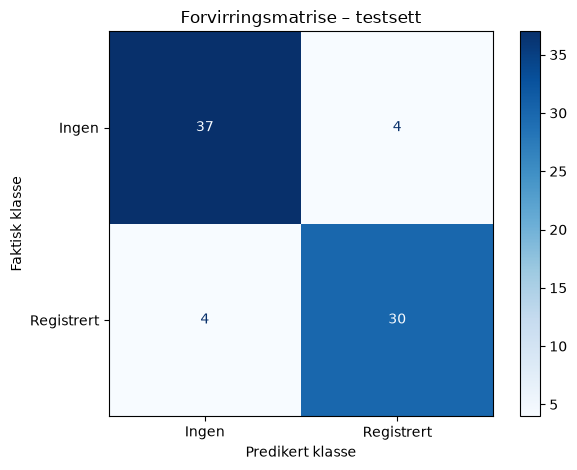

In [98]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(
    confusion_matrix=matrise_test,
    display_labels=["Ingen", "Registrert"]
).plot(cmap="Blues", values_format="d")

plt.title("Forvirringsmatrise – testsett")
plt.xlabel("Predikert klasse")
plt.ylabel("Faktisk klasse")
plt.tight_layout()
plt.savefig("forvirringsmatrise.png", dpi=300)
plt.show()